## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sherlock Chen

**Date:** 10/10/2026

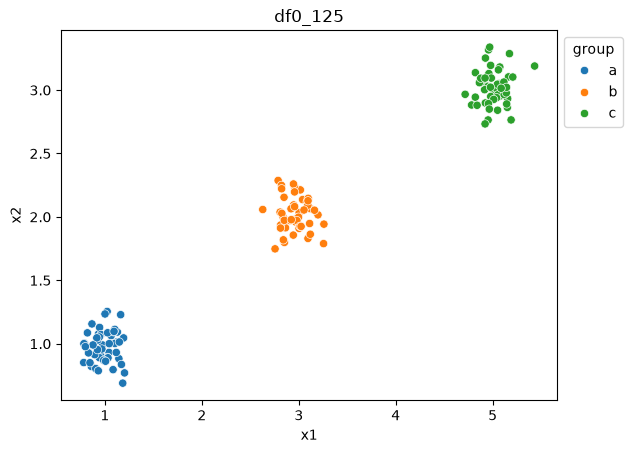

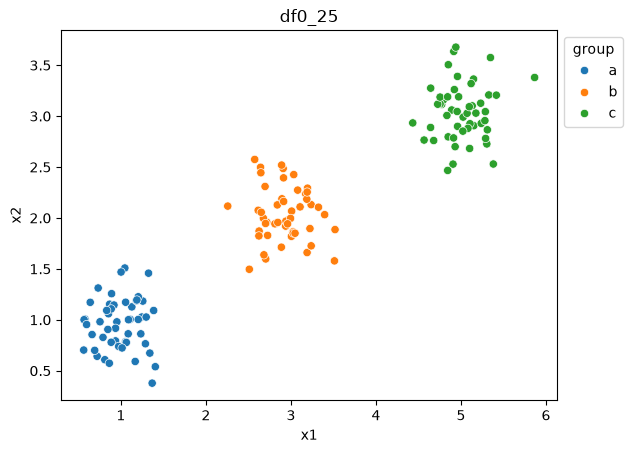

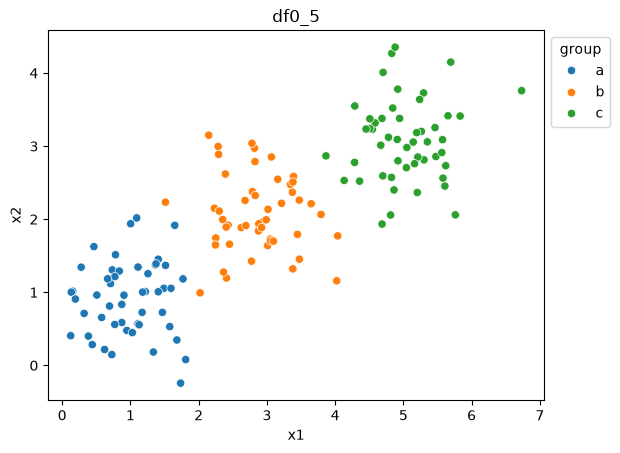

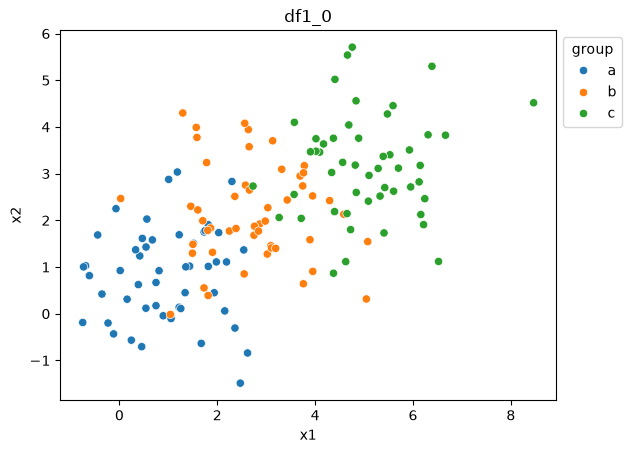

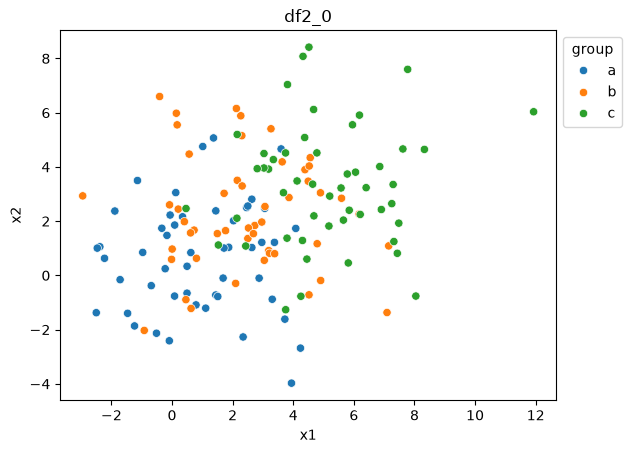

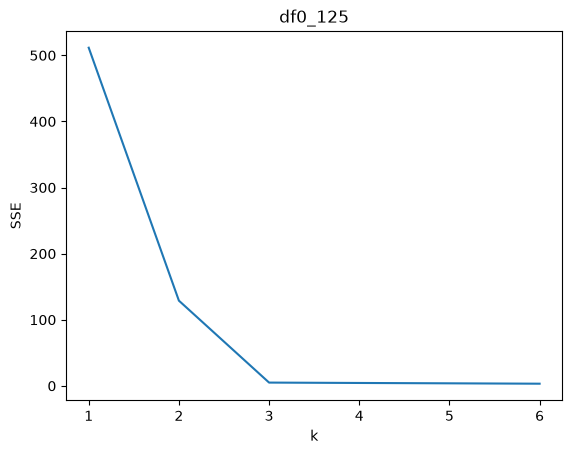

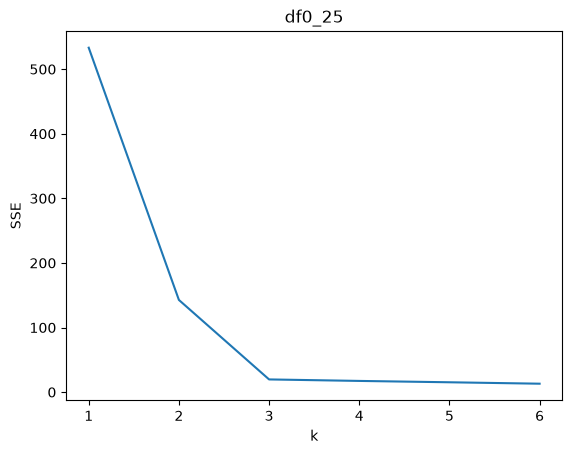

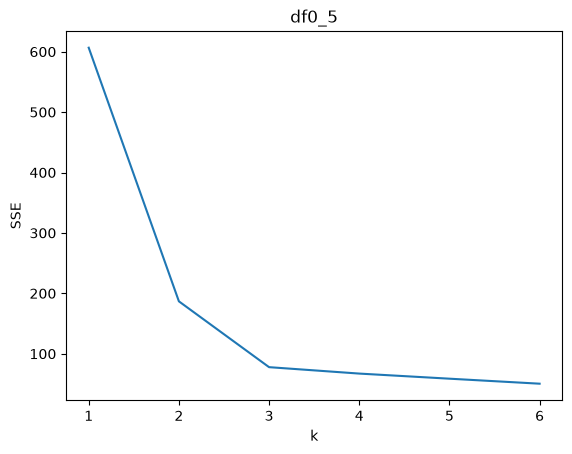

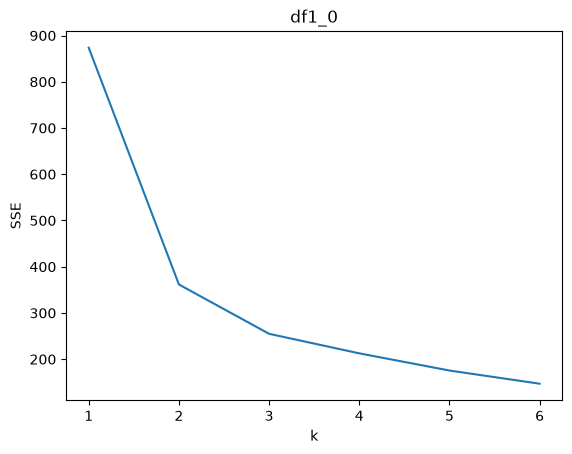

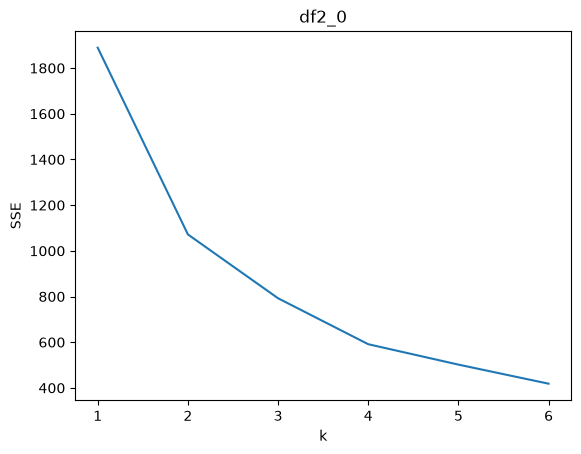

In [ ]:
# Question 1.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Question 1.2

# As the noise goes up, the three clusters become less and less separated into their own groups. They become more spread out and interwoven with each other making them hard to differentiate.
ax = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("df0_125")
plt.show()

ax = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("df0_25")
plt.show()

ax = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("df0_5")
plt.show()

ax = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("df1_0")
plt.show()

ax = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("df2_0")
plt.show()

# Question 1.3

# As the level of noise increases, the elbow in the scree plot becomes less defined, which makes it harder to choose a distinctive k for the elbow.
# Additionally, as noise increases, the SSE also increases, from highest being around 500 in the first plot to highest being around 1800 in the last plot.
ks = np.arange(1, 7)

X1 = df0_125[["x1", "x2"]]
SSE1 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X1)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE1).set(title="df0_125", xlabel="k", ylabel="SSE")
plt.show()

X2 = df0_25[["x1", "x2"]]
SSE2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X2)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE2).set(title="df0_25", xlabel="k", ylabel="SSE")
plt.show()

X3 = df0_5[["x1", "x2"]]
SSE3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE3).set(title="df0_5", xlabel="k", ylabel="SSE")
plt.show()

X4 = df1_0[["x1", "x2"]]
SSE4 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X4)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE4).set(title="df1_0", xlabel="k", ylabel="SSE")
plt.show()

X5 = df2_0[["x1", "x2"]]
SSE5 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X5)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE5).set(title="df2_0", xlabel="k", ylabel="SSE")
plt.show()

# Question 1.4
# The intuition of the elbow is that as k goes up, the SSE drops. 
# For example, in the scree plots for these datasets, the SSE drops a lot from when k is 1 to k is around 3, then the SSE levels after out meaning that adding more clusters to the already there 3 groups has little effect.


148
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
Spending (2020 USD)               False
Percent of GDP                    False
Percent of Government Spending    False
Spending per Capita               False
dtype: bool
     Spending (2020 USD)  Spending per Capita
min                  0.0                  0.0
max                  1.0                  1.0


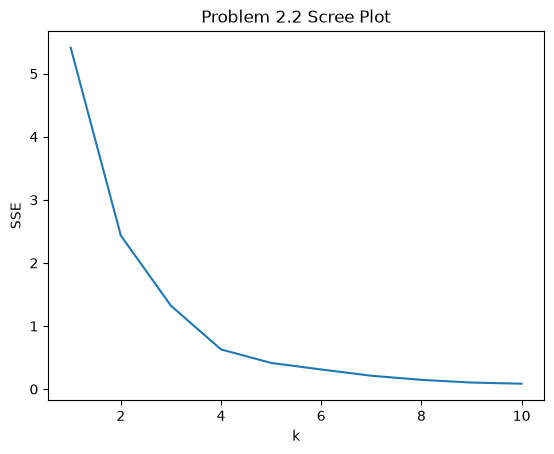

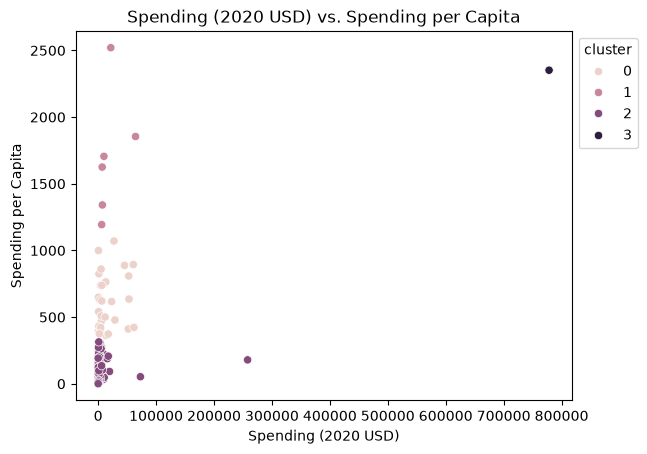

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.20

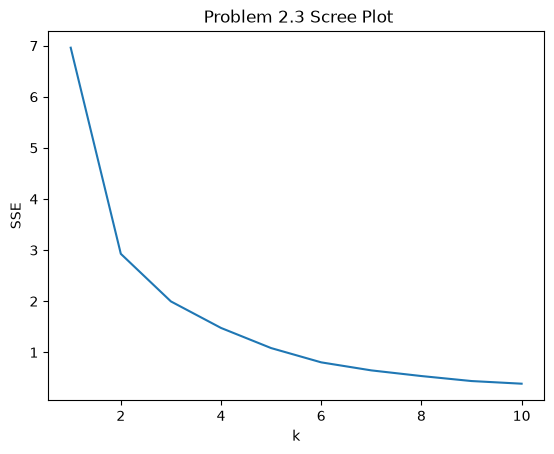

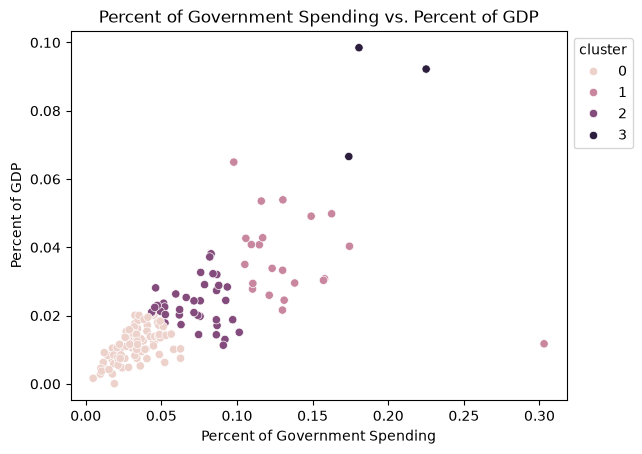

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 86.0  0.033019  0.013198  0.004896   
1                                 22.0  0.136158  0.042661  0.097882   
2                                 37.0  0.072669  0.016870  0.043592   
3                                  3.0  0.193209  0.027779  0.173924   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.022977  0.032821  0.042267  0.062685           86.0  0.011394   
1        0.111561  0.126638  0.146304  0.303027           22.0  0.036932   
2        0.059520  0.075583  0.086497  0.101501           37.0  0.023079   
3        0.177289  0.180654  0.202852  

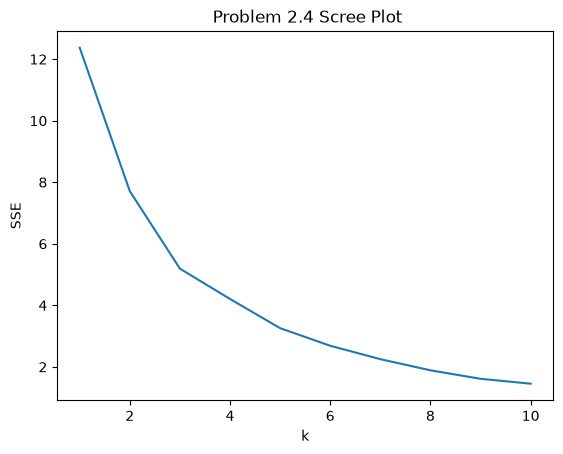

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      86.0    4513.543790  27841.230783       8.622460   
1                       1.0  778397.200000           NaN  778397.200000   
2                      30.0    9073.543709  18135.032885     163.926877   
3                      26.0   15330.618681  18923.469359     405.790494   
4                       5.0   21878.058451  24674.937388    6095.708713   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0            81.022976     288.061512    1138.618231  257973.429834   
1        778397.200000  778397.200000  778397.200000  778397.200000   
2           522.737081    1663.090134    864

In [ ]:
# Question 2.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

path = "data/SIPRI Military Expenditure Database.csv"
df = pd.read_csv(path)

df_clean = df[df["Year"] == 2020]
df_clean = df_clean.dropna()

# checked that there are indeed 148 countries left
countries = df_clean["Country"].unique()
print(len(countries))

# checking if dataset needs any more cleaning
print(df_clean.dtypes)
check_negative = (df_clean[["Spending (2020 USD)", "Percent of GDP", "Percent of Government Spending", "Spending per Capita"]] < 0).any()
print(check_negative)

# Question 2.2

# Min-max normalizing
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_clean.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
print(X.agg(["min", "max"]))

# Finding optimal k
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Problem 2.2 Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# Create scatterplot
# Optimal k is 4 since that seems to be where the elbow is from scree plot
optimal_k = 4
model = KMeans(n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0).fit(X)
df_clean["cluster"] = model.labels_
ax = sns.scatterplot(data=df_clean, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Spending (2020 USD) vs. Spending per Capita")
plt.show()

# Describe table
describe_table = df_clean.groupby("cluster")[["Spending (2020 USD)", "Spending per Capita"]].describe()
print(describe_table)

# Find US in describe table
us_filter = df_clean[df_clean["Country"] == "United States of America"]
print(us_filter[["Country", "cluster", "Spending (2020 USD)", "Spending per Capita"]])

# The US is in cluster 3 with spending of 778397.2 and spending per capita of 2351.631858
# I see that cluster 2 generally has the least spending among the four clusters and it also has the highest count. Cluster 3 has the most spending but it's count is just 1, which is the US. Clusters 0 and 1 have the rest of the countries with spending between clusters 2 and 3.

# Question 2.3

# Min-max normalizing
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df_clean.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
print(X.agg(["min", "max"]))

# Finding optimal k
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title=" Problem 2.3 Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# Create scatterplot
# Optimal k is 4 since that seems to be where the elbow is from scree plot
optimal_k = 4
model = KMeans(n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0).fit(X)
df_clean["cluster"] = model.labels_
ax = sns.scatterplot(data=df_clean, x="Percent of Government Spending", y="Percent of GDP", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Percent of Government Spending vs. Percent of GDP")
plt.show()

# Describe table
describe_table = df_clean.groupby("cluster")[["Percent of Government Spending", "Percent of GDP"]].describe()
print(describe_table)

# Find US in describe table
us_filter = df_clean[df_clean["Country"] == "United States of America"]
print(us_filter[["Country", "cluster", "Percent of Government Spending", "Percent of GDP"]])

# In part 2, the US was isolated into its own cluster but this time, it is in cluster 2 which has 36 other countries in it.
# Additionally, most of the countries in part 2 were low spending while in part 3, the countries are more distributed with no one cluster having the majority of countries.

# Question 2.4

# Min-max normalizing
features = ["Spending (2020 USD)", "Percent of Government Spending", "Percent of GDP", "Spending per Capita"]
unscaled = df_clean.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
print(X.agg(["min", "max"]))

# Finding optimal k
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title=" Problem 2.4 Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

# Create scatterplot
# Optimal k is 5 since that seems to be where the elbow is from scree plot
optimal_k = 5
model = KMeans(n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0).fit(X)
df_clean["cluster"] = model.labels_

# Describe table
describe_table = df_clean.groupby("cluster")[["Spending (2020 USD)", "Percent of Government Spending", "Percent of GDP", "Spending per Capita"]].describe()
print(describe_table)

# Find US in describe table
us_filter = df_clean[df_clean["Country"] == "United States of America"]
print(us_filter[["Country", "cluster", "Spending (2020 USD)", "Percent of Government Spending", "Percent of GDP", "Spending per Capita"]])

# Similar to part 2, US is also isolated in its own cluster (cluster 1) in part 4. This is because even though the US is similar in percentages to other countries, its spending is much higher which causes it to be in a group of its own.
# The optimal k is also different (k=5) than from the other two parts (k=4). Additionally, the clusters are also more evenly spread out than part 2 since not a single cluster has almost all the countries, similar to part 3.

# Question 2.5

# Yes, the K means clustering algorithm found useful patterns for me. It helped me find that countries with higher spending didn't necessarily mean they spent more of their percentage of budget on it. For example, US spent the most money but percentage wise, it didn't spend much more than most other countries.
# Another pattern it showed was that most countries spend little on military and that only some countries spend a lot.  


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]